# Loan Approval Prediction Using Ensemble Learning (RF, XGBoost and LightGBM)

**Roll Numbers:** ____________________
**Department:** Computer Science Engineering

This notebook builds a machine learning system that predicts whether a loan application will be approved or rejected using Random Forest, XGBoost, and LightGBM. The workflow follows data exploration, preprocessing, model training, evaluation, feature importance, and applicant risk analysis.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve, classification_report
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import warnings
warnings.filterwarnings('ignore')

## 2. Load the Dataset

We use `loan_approval.csv`, a self-generated dataset containing 5,000 loan applications and 16 applicant/loan attributes such as income, employment experience, loan amount, credit score, debt-to-income ratio, education, property area, savings, and co-applicant income.

In [2]:
df = pd.read_csv('loan_approval.csv')
print('Dataset shape:', df.shape)
df.head()

Dataset shape: (5000, 16)


,Age,AnnualIncome,EmploymentYears,LoanAmount,LoanTermMonths,CreditScore,DebtToIncomeRatio,ExistingLoans,Education,SelfEmployed,Married,Dependents,PropertyArea,Savings,CoApplicantIncome,LoanApproved
0,59,114400.0,24,60200.0,48,0.40,0.10,0,Graduate,No,Yes,0,Rural,9700.0,14300.0,Rejected
1,49,NaN,25,137300.0,24,0.46,0.12,2,Not Graduate,No,Yes,4,Semiurban,16800.0,11500.0,Approved
2,35,136000.0,1,61900.0,36,0.90,0.23,3,Not Graduate,No,No,1,Urban,6100.0,31000.0,Approved
3,63,36800.0,13,57500.0,24,0.81,0.28,3,Not Graduate,No,Yes,3,Rural,18700.0,47700.0,Approved
4,28,47200.0,21,59400.0,36,0.99,0.24,5,Graduate,No,No,2,Urban,23800.0,27600.0,Approved


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                5000 non-null   int64  
 1   AnnualIncome       4900 non-null   float64
 2   EmploymentYears    5000 non-null   int64  
 3   LoanAmount         4900 non-null   float64
 4   LoanTermMonths     5000 non-null   int64  
 5   CreditScore        4900 non-null   float64
 6   DebtToIncomeRatio  4900 non-null   float64
 7   ExistingLoans      5000 non-null   int64  
 8   Education          4900 non-null   object 
 9   SelfEmployed       5000 non-null   object 
 10  Married            5000 non-null   object 
 11  Dependents         5000 non-null   int64  
 12  PropertyArea       5000 non-null   object 
 13  Savings            5000 non-null   float64
 14  CoApplicantIncome  5000 non-null   float64
 15  LoanApproved       5000 non-null   object 
dtypes: float64(6), int64(5),

In [4]:
print('Missing values:\n', df.isnull().sum())
print('\nTarget distribution:\n', df['LoanApproved'].value_counts())

Missing values:
 Age                    0
AnnualIncome         100
EmploymentYears        0
LoanAmount           100
LoanTermMonths         0
CreditScore          100
DebtToIncomeRatio    100
ExistingLoans          0
Education            100
SelfEmployed           0
Married                0
Dependents             0
PropertyArea           0
Savings                0
CoApplicantIncome      0
LoanApproved           0
dtype: int64

Target distribution:
 LoanApproved
Approved    4007
Rejected     993
Name: count, dtype: int64


## 3. Exploratory Data Analysis (EDA)

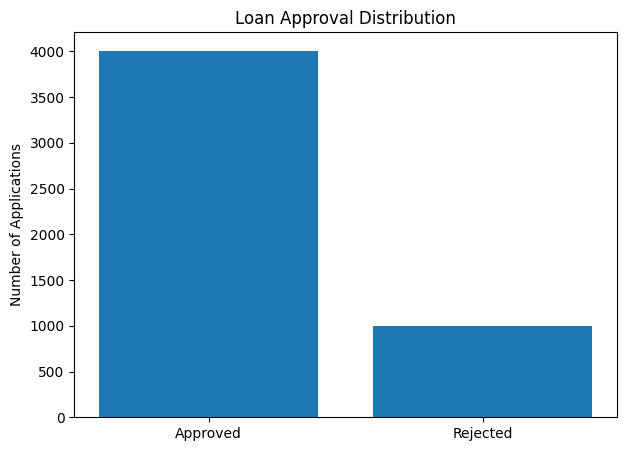

LoanApproved
Approved    80.14
Rejected    19.86
Name: proportion, dtype: float64


In [5]:
plt.figure(figsize=(7,5))
counts = df['LoanApproved'].value_counts()
plt.bar(counts.index, counts.values)
plt.title('Loan Approval Distribution')
plt.ylabel('Number of Applications')
plt.show()
print(df['LoanApproved'].value_counts(normalize=True) * 100)

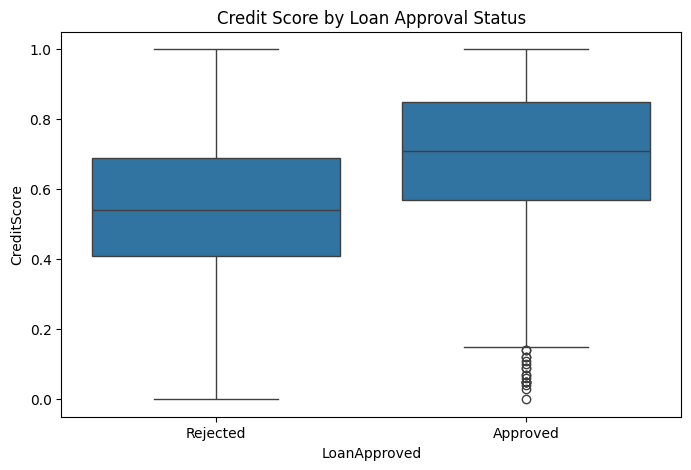

In [6]:
plt.figure(figsize=(8,5))
sns.boxplot(x='LoanApproved', y='CreditScore', data=df)
plt.title('Credit Score by Loan Approval Status')
plt.show()

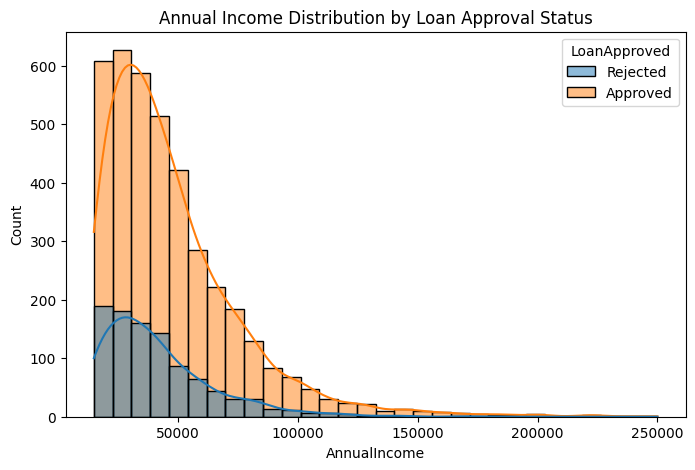

In [7]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x='AnnualIncome', hue='LoanApproved', bins=30, kde=True)
plt.title('Annual Income Distribution by Loan Approval Status')
plt.show()

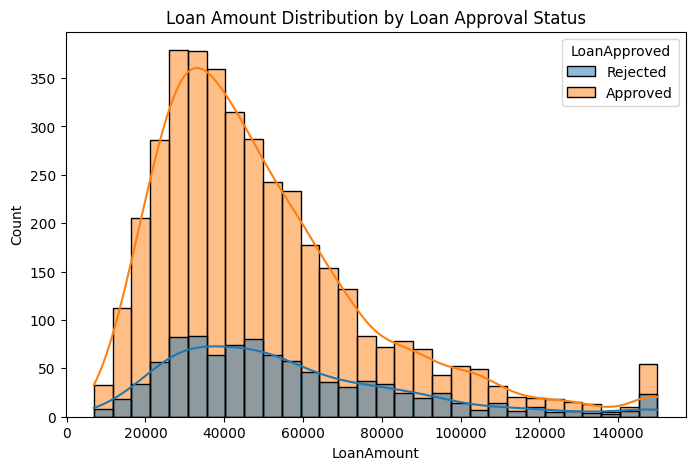

In [8]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x='LoanAmount', hue='LoanApproved', bins=30, kde=True)
plt.title('Loan Amount Distribution by Loan Approval Status')
plt.show()

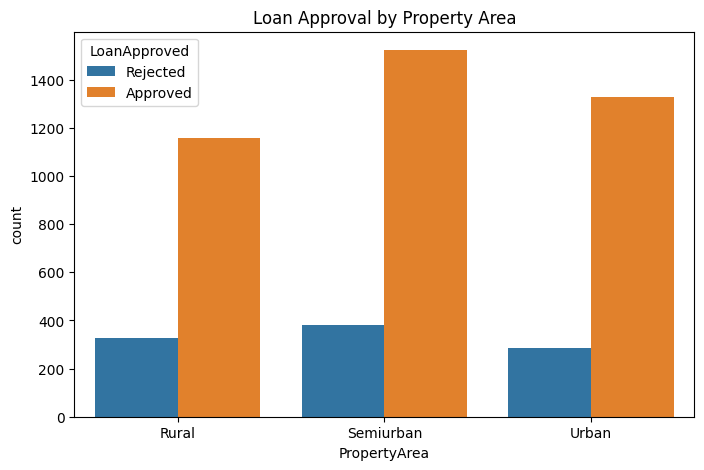

In [9]:
plt.figure(figsize=(8,5))
sns.countplot(x='PropertyArea', hue='LoanApproved', data=df)
plt.title('Loan Approval by Property Area')
plt.show()

### Correlation Analysis

Correlation shows the strength and direction of the linear relationship between numerical variables. The heatmap below also includes the encoded loan approval target (`1 = Approved`, `0 = Rejected`). A correlation value close to +1 indicates a strong positive relationship, while a value close to -1 indicates a strong negative relationship.

Correlation Matrix:


,Age,AnnualIncome,EmploymentYears,LoanAmount,LoanTermMonths,CreditScore,DebtToIncomeRatio,ExistingLoans,Dependents,Savings,CoApplicantIncome,LoanApproved
Age,1.00,0.02,0.01,-0.02,0.02,0.01,0.02,0.02,-0.01,0.02,0.01,-0.00
AnnualIncome,0.02,1.00,0.01,0.02,0.01,0.02,0.01,0.02,0.01,-0.02,-0.00,0.08
EmploymentYears,0.01,0.01,1.00,-0.02,-0.00,0.00,-0.02,-0.03,-0.00,0.02,-0.02,0.15
LoanAmount,-0.02,0.02,-0.02,1.00,0.00,-0.01,0.02,-0.02,0.01,0.01,-0.02,-0.09
LoanTermMonths,0.02,0.01,-0.00,0.00,1.00,-0.00,-0.03,0.01,-0.01,-0.01,0.01,0.01
CreditScore,0.01,0.02,0.00,-0.01,-0.00,1.00,-0.02,-0.01,-0.00,-0.03,0.02,0.29
DebtToIncomeRatio,0.02,0.01,-0.02,0.02,-0.03,-0.02,1.00,-0.01,0.01,0.01,-0.00,-0.09
ExistingLoans,0.02,0.02,-0.03,-0.02,0.01,-0.01,-0.01,1.00,0.03,-0.01,-0.00,-0.03
Dependents,-0.01,0.01,-0.00,0.01,-0.01,-0.00,0.01,0.03,1.00,-0.01,-0.02,-0.06
Savings,0.02,-0.02,0.02,0.01,-0.01,-0.03,0.01,-0.01,-0.01,1.00,-0.00,-0.00


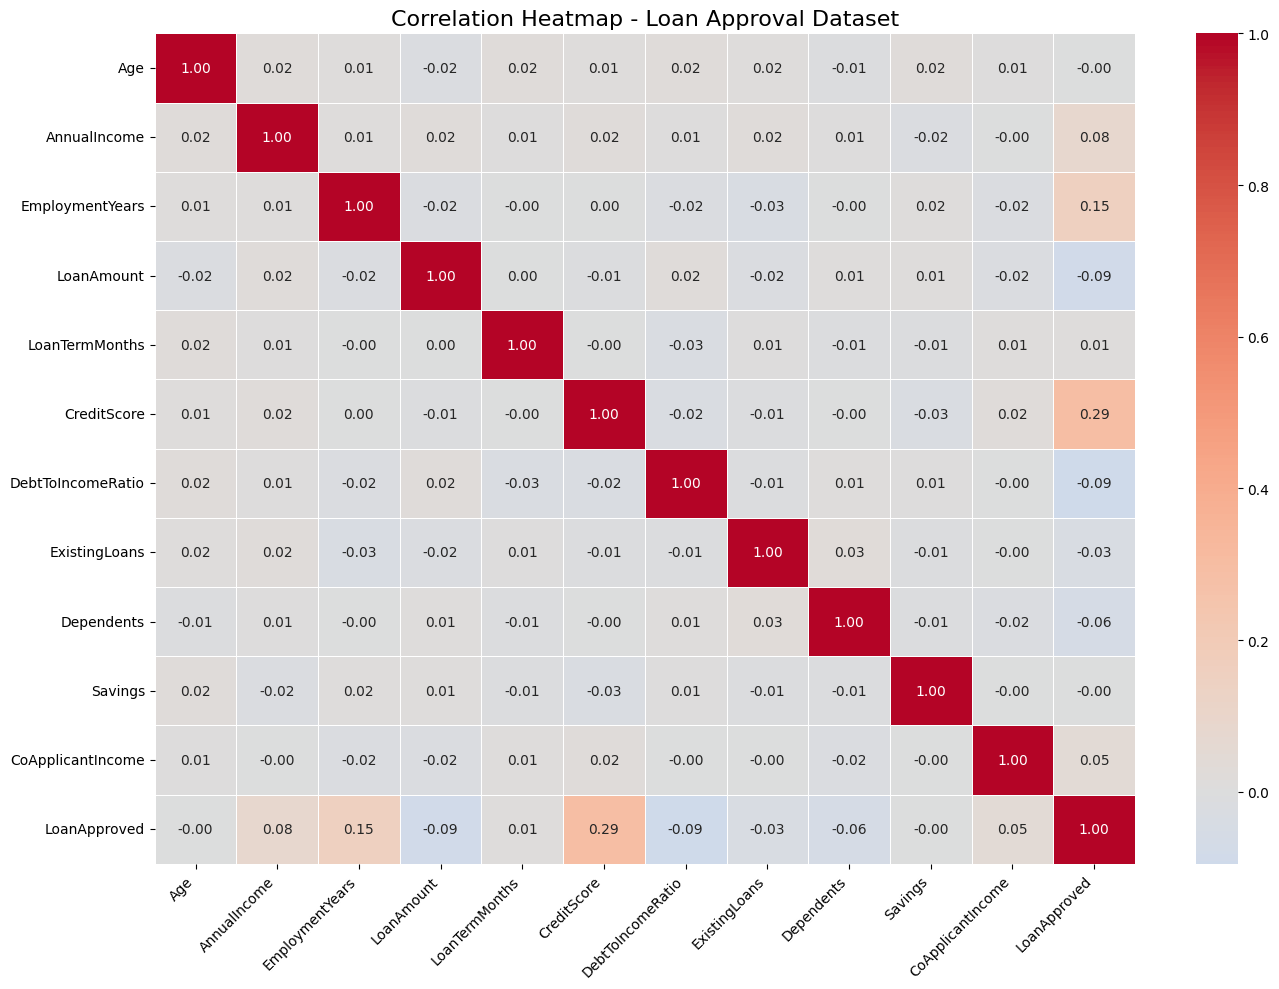

Correlation with Loan Approval:


,Correlation
CreditScore,0.29
EmploymentYears,0.15
AnnualIncome,0.08
CoApplicantIncome,0.05
LoanTermMonths,0.01
Age,-0.00
Savings,-0.00
ExistingLoans,-0.03
Dependents,-0.06
LoanAmount,-0.09


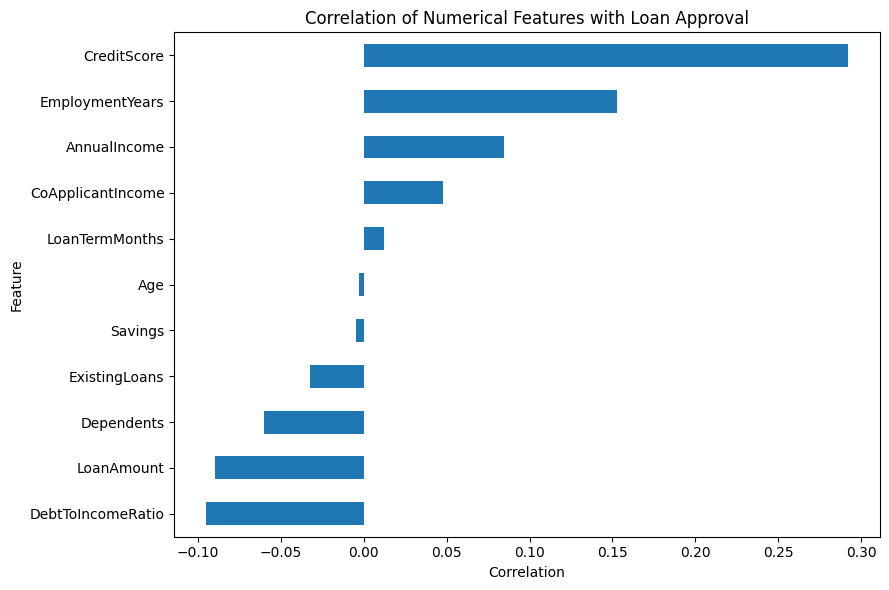

In [10]:
# CORRELATION ANALYSIS
corr_data = df.copy()
corr_data['LoanApproved'] = corr_data['LoanApproved'].map({'Rejected': 0, 'Approved': 1})

# Select all numerical variables
numeric_corr = corr_data.select_dtypes(include=[np.number])
corr_matrix = numeric_corr.corr()

# Display the correlation matrix
print("Correlation Matrix:")
display(corr_matrix.round(2))

# Plot correlation heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap - Loan Approval Dataset", fontsize=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Correlation of each numerical feature with loan approval
target_corr = corr_matrix['LoanApproved'].drop('LoanApproved').sort_values(ascending=False)
print("Correlation with Loan Approval:")
display(target_corr.round(2).to_frame("Correlation"))

plt.figure(figsize=(9, 6))
target_corr.sort_values().plot(kind="barh")
plt.title("Correlation of Numerical Features with Loan Approval")
plt.xlabel("Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


## 5. Data Preprocessing

Steps:
1. Separate the target variable `LoanApproved`.
2. Convert the target into binary values: Approved = 1 and Rejected = 0.
3. Separate numerical and categorical features.
4. Fill missing numerical values using the median and categorical values using the most frequent category.
5. One-hot encode categorical variables.
6. Split the data into training and testing sets using stratification.

In [11]:
data = df.copy()
data['LoanApproved'] = data['LoanApproved'].map({'Rejected': 0, 'Approved': 1})
X = data.drop(columns=['LoanApproved'])
y = data['LoanApproved']

numeric_features = X.select_dtypes(include=['int64','float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_features),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Train size:', X_train.shape)
print('Test size:', X_test.shape)

Train size: (4000, 15)
Test size: (1000, 15)


## 6. Model 1 — Random Forest

In [12]:
rf = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, class_weight='balanced'))
])
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]
print('Random Forest trained successfully.')

Random Forest trained successfully.


## 7. Model 2 — XGBoost

In [13]:
xgb = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05, eval_metric='logloss', random_state=42))
])
xgb.fit(X_train, y_train)
xgb_pred = xgb.predict(X_test)
xgb_proba = xgb.predict_proba(X_test)[:, 1]
print('XGBoost trained successfully.')

XGBoost trained successfully.


## 8. Model 3 — LightGBM

In [14]:
lgbm = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LGBMClassifier(n_estimators=300, max_depth=-1, learning_rate=0.05, num_leaves=31, random_state=42, verbosity=-1))
])
lgbm.fit(X_train, y_train)
lgbm_pred = lgbm.predict(X_test)
lgbm_proba = lgbm.predict_proba(X_test)[:, 1]
print('LightGBM trained successfully.')

LightGBM trained successfully.


## 9. Model Evaluation

In [15]:
def get_metrics(name, y_true, y_pred, y_proba):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_proba)
    }

results = pd.DataFrame([
    get_metrics('Random Forest', y_test, rf_pred, rf_proba),
    get_metrics('XGBoost', y_test, xgb_pred, xgb_proba),
    get_metrics('LightGBM', y_test, lgbm_pred, lgbm_proba)
]).set_index('Model')

print(results.round(3))

               Accuracy  Precision  Recall  F1-Score  ROC-AUC
Model                                                        
Random Forest     0.785      0.834   0.913     0.872    0.747
XGBoost           0.803      0.825   0.956     0.886    0.729
LightGBM          0.809      0.825   0.966     0.890    0.735


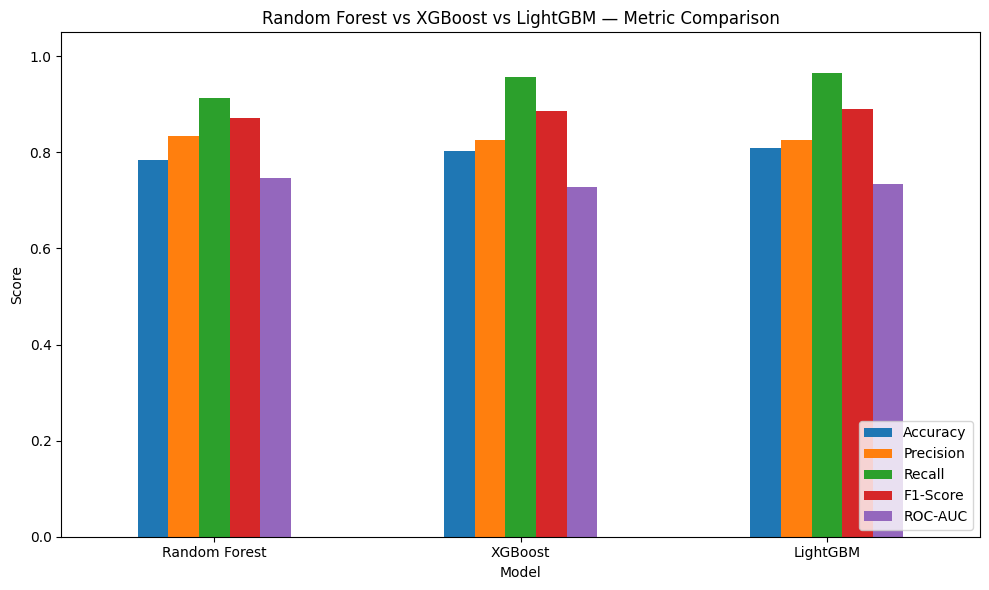

In [16]:
results.round(3).plot(kind='bar', figsize=(10,6))
plt.title('Random Forest vs XGBoost vs LightGBM — Metric Comparison')
plt.ylabel('Score')
plt.ylim(0,1.05)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Confusion Matrices

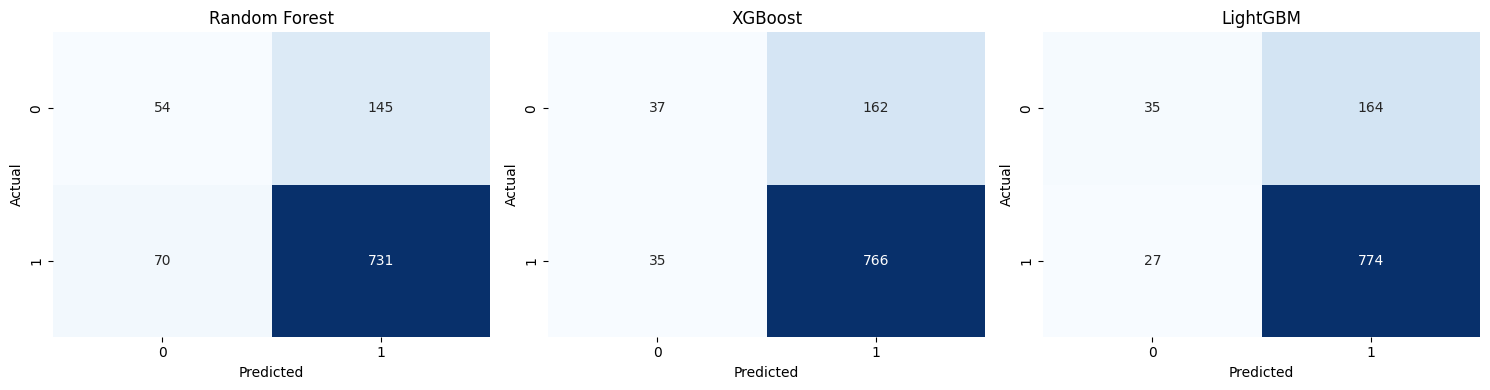

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, [('Random Forest', rf_pred), ('XGBoost', xgb_pred), ('LightGBM', lgbm_pred)]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

### ROC Curves

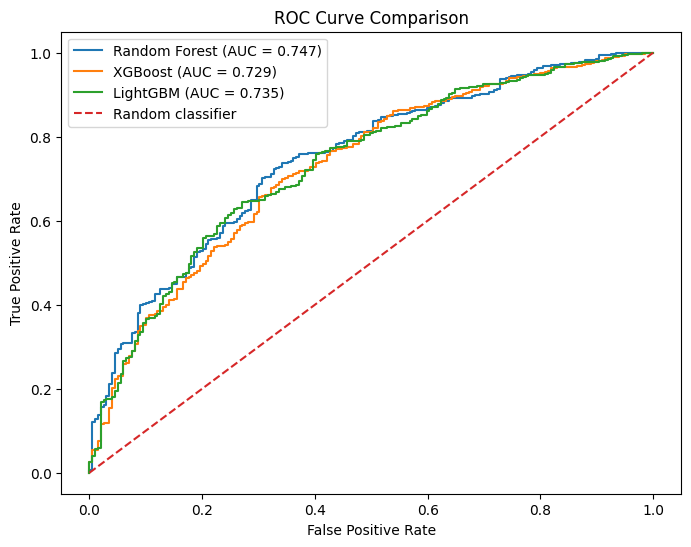

In [18]:
plt.figure(figsize=(8,6))
for name, proba in [('Random Forest', rf_proba), ('XGBoost', xgb_proba), ('LightGBM', lgbm_proba)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')
plt.plot([0,1], [0,1], '--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.show()

### Detailed Classification Reports

In [19]:
print('Random Forest:\n', classification_report(y_test, rf_pred, target_names=['Rejected','Approved']))
print('XGBoost:\n', classification_report(y_test, xgb_pred, target_names=['Rejected','Approved']))
print('LightGBM:\n', classification_report(y_test, lgbm_pred, target_names=['Rejected','Approved']))

Random Forest:
               precision    recall  f1-score   support

    Rejected       0.44      0.27      0.33       199
    Approved       0.83      0.91      0.87       801

    accuracy                           0.79      1000
   macro avg       0.63      0.59      0.60      1000
weighted avg       0.76      0.79      0.76      1000

XGBoost:
               precision    recall  f1-score   support

    Rejected       0.51      0.19      0.27       199
    Approved       0.83      0.96      0.89       801

    accuracy                           0.80      1000
   macro avg       0.67      0.57      0.58      1000
weighted avg       0.76      0.80      0.76      1000

LightGBM:
               precision    recall  f1-score   support

    Rejected       0.56      0.18      0.27       199
    Approved       0.83      0.97      0.89       801

    accuracy                           0.81      1000
   macro avg       0.69      0.57      0.58      1000
weighted avg       0.77      0.81    

## 10. Feature Importance

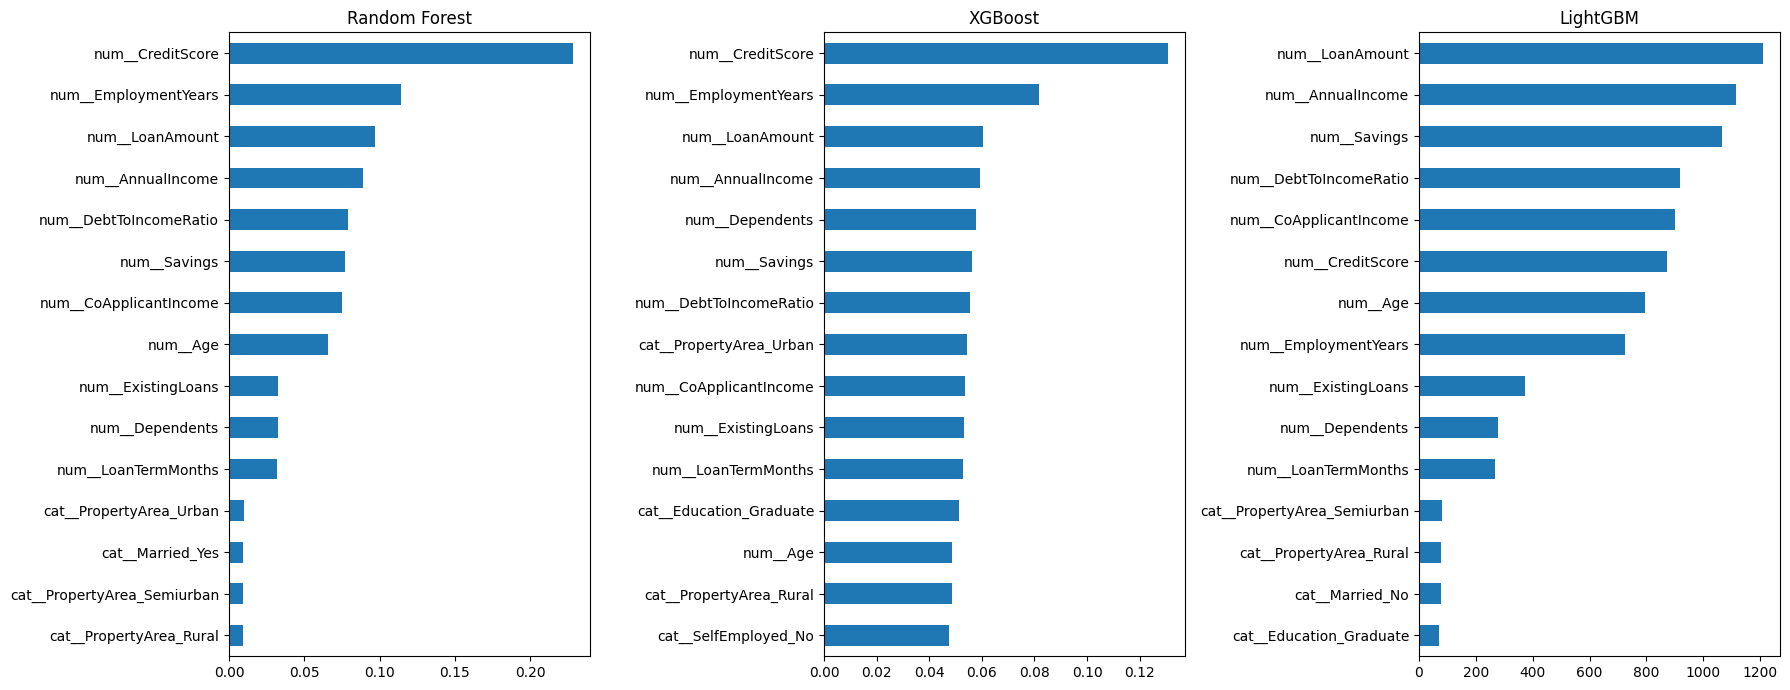

In [20]:
# Get feature names after preprocessing
feature_names = rf.named_steps['preprocessor'].get_feature_names_out()
rf_importance = pd.Series(rf.named_steps['model'].feature_importances_, index=feature_names).sort_values(ascending=False).head(15)
xgb_importance = pd.Series(xgb.named_steps['model'].feature_importances_, index=feature_names).sort_values(ascending=False).head(15)
lgbm_importance = pd.Series(lgbm.named_steps['model'].feature_importances_, index=feature_names).sort_values(ascending=False).head(15)

fig, axes = plt.subplots(1, 3, figsize=(18,7))
rf_importance.sort_values().plot(kind='barh', ax=axes[0])
axes[0].set_title('Random Forest')
xgb_importance.sort_values().plot(kind='barh', ax=axes[1])
axes[1].set_title('XGBoost')
lgbm_importance.sort_values().plot(kind='barh', ax=axes[2])
axes[2].set_title('LightGBM')
plt.tight_layout()
plt.show()

## 11. Which loan applications are most likely to be approved?

`predict_proba()` gives an approval probability between 0 and 1. We use the model probabilities to identify high-confidence approval predictions in the test set.

In [21]:
risk_table = X_test.copy()
risk_table['Actual_Approval'] = y_test.values
risk_table['RF_Approval_Probability'] = rf_proba
risk_table['XGB_Approval_Probability'] = xgb_proba
risk_table['LightGBM_Approval_Probability'] = lgbm_proba

top_approval_applications = risk_table.sort_values('LightGBM_Approval_Probability', ascending=False).head(20)
print('Top 20 applications with highest LightGBM approval probability:')
display(top_approval_applications[['Age','AnnualIncome','LoanAmount','CreditScore','DebtToIncomeRatio','Actual_Approval','LightGBM_Approval_Probability']])

Top 20 applications with highest LightGBM approval probability:


,Age,AnnualIncome,LoanAmount,CreditScore,DebtToIncomeRatio,Actual_Approval,LightGBM_Approval_Probability
1203,21,27500.0,31500.0,0.75,0.29,1,0.999466
2845,23,33300.0,29100.0,1.00,0.23,1,0.998912
4910,28,87600.0,12300.0,0.88,0.16,1,0.998876
881,56,142800.0,19900.0,1.00,0.23,1,0.998195
1444,36,126900.0,29800.0,0.71,0.11,1,0.997913
1098,24,41500.0,13600.0,0.80,0.15,1,0.997621
1122,41,74200.0,12200.0,0.84,0.39,1,0.997285
2540,25,165100.0,21400.0,0.78,0.23,1,0.997071
3779,36,40100.0,19600.0,0.94,0.13,1,0.997037
1021,53,55600.0,27300.0,0.86,0.20,1,0.996686


In [22]:
high_confidence = risk_table[risk_table['LightGBM_Approval_Probability'] >= 0.80]
print(f'Applications with LightGBM approval probability >= 0.80: {len(high_confidence)}')
if len(high_confidence) > 0:
    hit_rate = high_confidence['Actual_Approval'].mean() * 100
    print(f'Actual approval rate among these applications: {hit_rate:.1f}%')

Applications with LightGBM approval probability >= 0.80: 718
Actual approval rate among these applications: 87.3%


## 12. Conclusion

In [23]:
best_model = results['ROC-AUC'].idxmax()
print(f"Based on the test-set metrics, {best_model} achieved the highest ROC-AUC of {results.loc[best_model, 'ROC-AUC']:.3f}.")
print('The three ensemble learning models were trained and evaluated on the same loan-approval test set.')
print('Credit score, income, loan amount, debt-to-income ratio and other applicant characteristics were analyzed as predictive factors.')
print('The comparison demonstrates how ensemble learning can support data-driven loan approval prediction while model outputs should be treated as decision-support rather than a replacement for financial review.')

Based on the test-set metrics, Random Forest achieved the highest ROC-AUC of 0.747.
The three ensemble learning models were trained and evaluated on the same loan-approval test set.
Credit score, income, loan amount, debt-to-income ratio and other applicant characteristics were analyzed as predictive factors.
The comparison demonstrates how ensemble learning can support data-driven loan approval prediction while model outputs should be treated as decision-support rather than a replacement for financial review.
